# Kazakhstan Apartment Prices — from Scraping to Prediction

End-to-end data science project on the Kazakhstan housing market:

1. **Collect** — scrape ~3,600 apartment-for-sale listings from [krisha.kz](https://krisha.kz) (180 pages)
2. **Clean** — handle missing values, parse rooms & area from listing titles, map cities to regions
3. **Explore** — distributions, area vs. rooms, correlations
4. **Model** — predict price with Linear Regression, Decision Tree and Random Forest

> The scraped dataset is not included in this repository. Run the scraping cell to collect fresh data.

## 1. Data collection — scraping krisha.kz

For each listing card the scraper extracts the title, price, address, views, city and publication date, then parses the **number of rooms** and **area (m²)** from the title with regular expressions. A 1-second delay between requests keeps the load on the site low.

In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import csv
import time

# Base URL
base_url1 = "https://krisha.kz/prodazha/kvartiry/?page="

# Headers to mimic a browser
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'
}

# Function to parse a single page
def parse_page(url):
    try:
        response = requests.get(url, headers=headers, timeout=10)  # Adding headers and timeout
        response.raise_for_status()  # Check for request errors

        # Create a BeautifulSoup object to parse HTML
        soup = BeautifulSoup(response.text, 'html.parser')

        # Extract all elements with class 'a-card__title' where apartment name and link are present
        titles = soup.find_all('a', class_='a-card__title')

        # Extract all elements with class 'a-card__price' where the price is present
        prices = soup.find_all('div', class_='a-card__price')

        # Extract all elements with class 'a-card__subtitle' where the address is present
        addresses = soup.find_all('div', class_='a-card__subtitle')

        # Extract all elements with class 'a-view-count status-item' where the views are present
        views = soup.find_all('span', class_='a-view-count status-item')

        # Extract city and published date information
        stats_elements = soup.find_all('div', class_='a-card__stats-item')
        cities = []
        published_days = []
#Regular expression
        for element in stats_elements:
            text = element.get_text(strip=True)
            if re.match(r'\d+\s\w+', text):  # If the text is a date (e.g., '29 нояб.')
                published_days.append(text)
            elif "Количество просмотров" not in text:
                cities.append(text)

        # List to store data
        data = []

        # Iterate over found elements and collect data
        for title, price, address, view, city, published_day in zip(titles, prices, addresses, views, cities, published_days):
            # Extract text which contains description (e.g., "4-комнатная квартира · 140 м²")
            description = title.get_text(strip=True)

            # Clean price by removing non-digit characters
            cleaned_price = re.sub(r'\D', '', price.get_text(strip=True))

            # Extract address
            address_text = address.get_text(strip=True)

            # Extract views
            views_count = view.get_text(strip=True)

            # Extract number of rooms and area using regular expressions
            rooms_match = re.search(r'(\d+)-комнатная', description)  # Search for number of rooms
            area_match = re.search(r'(\d+)\s*м²', description)  # Search for area in m²

            rooms = rooms_match.group(1) if rooms_match else "Не указано"
            area = area_match.group(1) if area_match else "Не указано"

            # Add data to list
            data.append([description, cleaned_price, address_text, rooms, area, views_count, city, published_day])

        return data

    except requests.exceptions.RequestException as e:
        # Handle any request issues (e.g., timeouts, DNS failures)
        print(f"Failed to retrieve page {url}. Error: {e}")
        return []  # Return an empty list if there's an error

# Function to scrape all pages
def scrape_all_pages(start_page=1, end_page=180):
    all_data = []
    for page in range(start_page, end_page + 1):
        url = f"{base_url1}{page}"
        print(f"Parsing page {page}...")
        page_data = parse_page(url)
        if page_data:  # If page data is not empty, add to the main list
            all_data.extend(page_data)
        time.sleep(1)  # Adding a short delay to prevent overwhelming the server

    return all_data

# Function to save data to CSV file
def save_to_csv(data, filename="apartments_data.csv"):
    # Open file for writing
    with open(filename, mode='w', newline='', encoding='utf-8') as file:
        writer = csv.writer(file)

        # Write headers
        writer.writerow(["Описание", "Цена (тенге)", "Адрес", "Количество комнат", "Площадь (м²)", "Просмотры", "Город", "Дата публикации"])

        # Write data
        writer.writerows(data)

# Run script: collect pages 1–180 and save to CSV
all_data = scrape_all_pages(start_page=1, end_page=180)
save_to_csv(all_data)

Parsing page 1...
Parsing page 2...
Parsing page 3...
...
Parsing page 179...
Parsing page 180...


## 2. Loading the raw data

In [10]:
import pandas as pd

# Step 1: Load CSV data into a DataFrame
filename = "apartments_data.csv"
df = pd.read_csv(filename)

In [12]:
df

,Описание,Цена (тенге),Адрес,Количество комнат,Площадь (м²),Просмотры,Город,Дата публикации
0,3-комнатная квартира · 78 м² · 9/9 этаж,35000000,Академика Сатпаева 348 — Теплова,3,78,NaN,Павлодар,29 нояб.
1,1-комнатная квартира · 56.8 м² · 14/16 этаж,20000000,"р-н Байконур, ул. Иманова",1,8,NaN,NaN,29 нояб.
2,1-комнатная квартира · 27 м²,16200000,Кулманова 113 Г,1,27,NaN,Астана,29 нояб.
3,3-комнатная квартира · 65 м² · 3/5 этаж,27000000,"Казыбек би р-н, мкр Михайловка",3,65,NaN,NaN,29 нояб.
4,3-комнатная квартира · 84 м² · 1/3 этаж,24500000,Сулейманова 270,3,84,NaN,Атырау,29 нояб.
...,...,...,...,...,...,...,...,...
3597,3-комнатная квартира · 60 м² · 2/5 этаж,14000000,Шұғыла 42,3,60,NaN,NaN,28 нояб.
3598,1-комнатная квартира · 37 м² · 5/5 этаж,25500000,"Жетысуский р-н, проспект Райымбека 167в — Ташк...",1,37,NaN,Алматы,28 нояб.
3599,2-комнатная квартира · 47 м² · 1/2 этаж,21000000,"Турксибский р-н, Суюнба 302 — Илийский тракт",2,47,NaN,NaN,28 нояб.
3600,2-комнатная квартира · 78.5 м² · 7/9 этаж,41000000,"Ауэзовский р-н, мкр Аксай-1А 27 — Райымбека Яс...",2,5,NaN,Астана,28 нояб.


## 3. Handling missing values

The *views* column is empty for every listing, so it is dropped. Missing cities are filled with a placeholder.

In [46]:
import pandas as pd

# Load the dataset from CSV
filename = "apartments_data.csv"
df = pd.read_csv(filename)

# 1: Check for missing values
print("Missing values before handling:")
print(df.isnull().sum())

# 2: Drop the 'Просмотры' (Views) column
df = df.drop('Просмотры', axis=1)

# 3: Handle missing values by imputation or removal
# Fill missing numeric values with median values and categorical values with "Не указано"
for column in df.columns:
    if df[column].dtype == 'object':  # Categorical column
        df[column] = df[column].fillna("Не указано")
    else:  # Numeric column
        df[column] = df[column].fillna(df[column].median())

# Step 4: Verify there are no more missing values
print("Missing values after handling:")
print(df.isnull().sum())

# Save the cleaned DataFrame to a new CSV file
df.to_csv("apartments_data_cleaned.csv", index=False)

df

Missing values before handling:
Описание                0
Цена (тенге)            0
Адрес                   0
Количество комнат       0
Площадь (м²)            0
Просмотры            3602
Город                1801
Дата публикации         0
dtype: int64
Missing values after handling:
Описание             0
Цена (тенге)         0
Адрес                0
Количество комнат    0
Площадь (м²)         0
Город                0
Дата публикации      0
dtype: int64


,Описание,Цена (тенге),Адрес,Количество комнат,Площадь (м²),Город,Дата публикации
0,3-комнатная квартира · 78 м² · 9/9 этаж,35000000,Академика Сатпаева 348 — Теплова,3,78,Павлодар,29 нояб.
1,1-комнатная квартира · 56.8 м² · 14/16 этаж,20000000,"р-н Байконур, ул. Иманова",1,8,Не указано,29 нояб.
2,1-комнатная квартира · 27 м²,16200000,Кулманова 113 Г,1,27,Астана,29 нояб.
3,3-комнатная квартира · 65 м² · 3/5 этаж,27000000,"Казыбек би р-н, мкр Михайловка",3,65,Не указано,29 нояб.
4,3-комнатная квартира · 84 м² · 1/3 этаж,24500000,Сулейманова 270,3,84,Атырау,29 нояб.
...,...,...,...,...,...,...,...
3597,3-комнатная квартира · 60 м² · 2/5 этаж,14000000,Шұғыла 42,3,60,Не указано,28 нояб.
3598,1-комнатная квартира · 37 м² · 5/5 этаж,25500000,"Жетысуский р-н, проспект Райымбека 167в — Ташк...",1,37,Алматы,28 нояб.
3599,2-комнатная квартира · 47 м² · 1/2 этаж,21000000,"Турксибский р-н, Суюнба 302 — Илийский тракт",2,47,Не указано,28 нояб.
3600,2-комнатная квартира · 78.5 м² · 7/9 этаж,41000000,"Ауэзовский р-н, мкр Аксай-1А 27 — Райымбека Яс...",2,5,Астана,28 нояб.


## 4. Feature engineering — cities → regions

Cities are grouped into five regions of Kazakhstan: **0** Central, **1** South, **2** West, **3** North, **4** East.

In [74]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# 1: Load the dataset from CSV
filename = "apartments_data_cleaned.csv"
df = pd.read_csv(filename)

# 2: Assign cities to geographical regions
region_mapping = {
    # Central Kazakhstan
    'Нур-Султан': 0, 'Астана': 0, 'Караганда': 0, 'Темиртау': 0, 'Балхаш': 0, 'Жезказган': 0, 'Сатпаев': 0,
    
    # South Kazakhstan
    'Алматы': 1, 'Шымкент': 1, 'Тараз': 1, 'Кызылорда': 1, 'Талдыкорган': 1, 'Туркестан': 1, 'Жетысай': 1, 
    'Сарыагаш': 1, 'Кентау': 1, 'Арысь': 1, 'Шу': 1,
    
    # West Kazakhstan
    'Актау': 2, 'Атырау': 2, 'Уральск': 2, 'Актобе': 2, 'Жанаозен': 2, 'Кульсары': 2, 'Байганин': 2, 'Хромтау': 2,
    
    # North Kazakhstan
    'Костанай': 3, 'Петропавловск': 3, 'Павлодар': 3, 'Экибастуз': 3, 'Рудный': 3, 'Лисаковск': 3, 'Житикара': 3,
    'Щучинск': 3, 'Степногорск': 3, 'Боровое': 3,

    # East Kazakhstan
    'Семей': 4, 'Усть-Каменогорск': 4, 'Оскемен': 4, 'Риддер': 4, 'Зыряновск': 4, 'Аягоз': 4, 'Шемонаиха': 4
}

# 3: Map the 'Город' column using the defined region mapping
df['Регион'] = df['Город'].map(region_mapping)

# Handle missing values in 'Регион' by setting it to a default value if necessary (e.g., Central = 0)
df['Регион'] = df['Регион'].fillna(0)

# Drop the original 'Город' column after encoding
df = df.drop('Город', axis=1)

# 4: Convert 'Количество комнат' from string to integer
df['Количество комнат'] = pd.to_numeric(df['Количество комнат'], errors='coerce')

# Step 7: Save the cleaned and processed DataFrame to a new CSV file
df.to_csv("apartments_data_plot.csv", index=False)

df

,Описание,Цена (тенге),Адрес,Количество комнат,Площадь (м²),Дата публикации,Регион
0,3-комнатная квартира · 78 м² · 9/9 этаж,35000000,Академика Сатпаева 348 — Теплова,3,78,29 нояб.,3.0
1,1-комнатная квартира · 56.8 м² · 14/16 этаж,20000000,"р-н Байконур, ул. Иманова",1,8,29 нояб.,0.0
2,1-комнатная квартира · 27 м²,16200000,Кулманова 113 Г,1,27,29 нояб.,0.0
3,3-комнатная квартира · 65 м² · 3/5 этаж,27000000,"Казыбек би р-н, мкр Михайловка",3,65,29 нояб.,0.0
4,3-комнатная квартира · 84 м² · 1/3 этаж,24500000,Сулейманова 270,3,84,29 нояб.,2.0
...,...,...,...,...,...,...,...
3597,3-комнатная квартира · 60 м² · 2/5 этаж,14000000,Шұғыла 42,3,60,28 нояб.,0.0
3598,1-комнатная квартира · 37 м² · 5/5 этаж,25500000,"Жетысуский р-н, проспект Райымбека 167в — Ташк...",1,37,28 нояб.,1.0
3599,2-комнатная квартира · 47 м² · 1/2 этаж,21000000,"Турксибский р-н, Суюнба 302 — Илийский тракт",2,47,28 нояб.,0.0
3600,2-комнатная квартира · 78.5 м² · 7/9 этаж,41000000,"Ауэзовский р-н, мкр Аксай-1А 27 — Райымбека Яс...",2,5,28 нояб.,0.0


## 5. Scaling & removing duplicates

In [100]:
# 5: Normalize or Scale Numerical Features to Standardize the Data
# Load your dataset
# Ensure 'Цена (тенге)' column exists
available_columns = df.columns
if 'Цена (тенге)' in available_columns:
    # Normalize only the "Цена (тенге)" column using MinMaxScaler
    scaler = MinMaxScaler()
    df[['Цена (тенге)']] = scaler.fit_transform(df[['Цена (тенге)']])

# 6: Correct Data Inconsistencies
# Remove duplicate rows if any
df = df.drop_duplicates()

df.to_csv("apartments_data_trainlast.csv", index=False)

df

,Описание,Цена (тенге),Адрес,Количество комнат,Площадь (м²),Город,Дата публикации
0,3-комнатная квартира · 78 м² · 9/9 этаж,0.001225,Академика Сатпаева 348 — Теплова,3,78,Павлодар,29 нояб.
1,1-комнатная квартира · 56.8 м² · 14/16 этаж,0.000658,"р-н Байконур, ул. Иманова",1,8,Не указано,29 нояб.
2,1-комнатная квартира · 27 м²,0.000514,Кулманова 113 Г,1,27,Астана,29 нояб.
3,3-комнатная квартира · 65 м² · 3/5 этаж,0.000923,"Казыбек би р-н, мкр Михайловка",3,65,Не указано,29 нояб.
4,3-комнатная квартира · 84 м² · 1/3 этаж,0.000828,Сулейманова 270,3,84,Атырау,29 нояб.
...,...,...,...,...,...,...,...
3597,3-комнатная квартира · 60 м² · 2/5 этаж,0.000431,Шұғыла 42,3,60,Не указано,28 нояб.
3598,1-комнатная квартира · 37 м² · 5/5 этаж,0.000866,"Жетысуский р-н, проспект Райымбека 167в — Ташк...",1,37,Алматы,28 нояб.
3599,2-комнатная квартира · 47 м² · 1/2 этаж,0.000696,"Турксибский р-н, Суюнба 302 — Илийский тракт",2,47,Не указано,28 нояб.
3600,2-комнатная квартира · 78.5 м² · 7/9 этаж,0.001452,"Ауэзовский р-н, мкр Аксай-1А 27 — Райымбека Яс...",2,5,Астана,28 нояб.


## 6. Exploratory data analysis

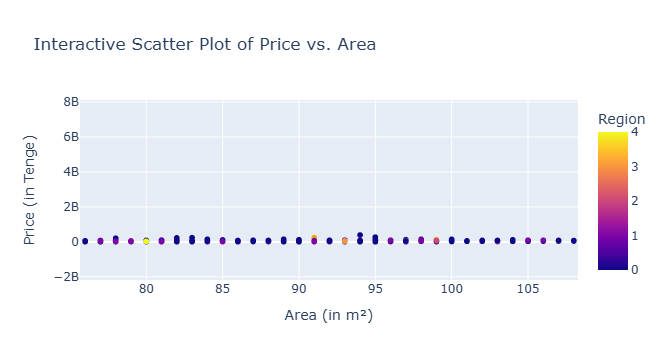

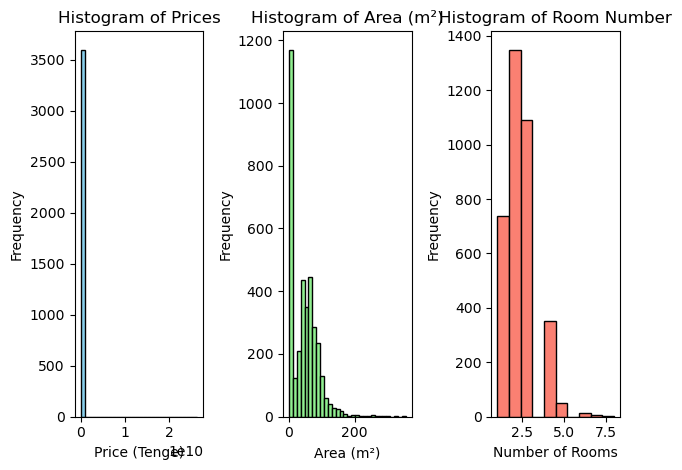

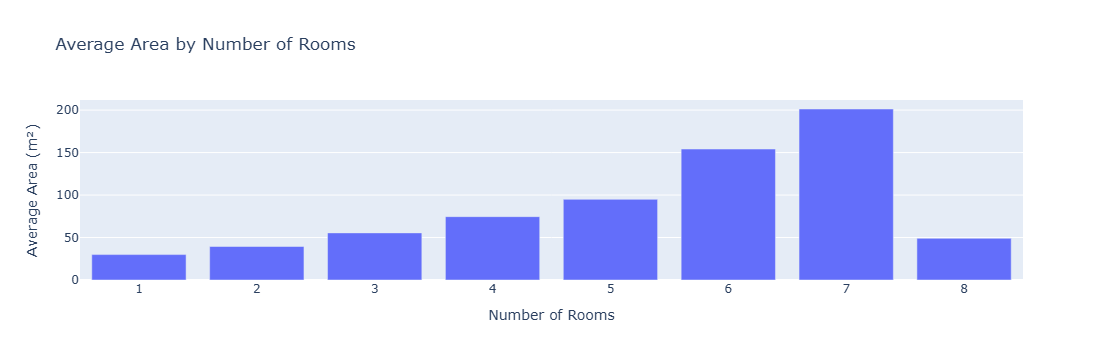

In [86]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt

# Load the processed dataset from 'apartments_data_plot.csv'
df = pd.read_csv("apartments_data_plot.csv")

# Step 1: Interactive Scatter Plot of Price vs. Area (in Square Meters)
fig_scatter = px.scatter(df, 
                         x='Площадь (м²)', 
                         y='Цена (тенге)', 
                         color='Регион',  # Use region as color to differentiate between regions
                         title='Interactive Scatter Plot of Price vs. Area',
                         labels={'Площадь (м²)': 'Area (in m²)', 'Цена (тенге)': 'Price (in Tenge)', 'Регион': 'Region'},
                         hover_data=['Описание', 'Адрес'])  # Adding additional information on hover

# Display the scatter plot
fig_scatter.show()

# Room Number Histogram
plt.subplot(1, 3, 3)
plt.hist(df['Количество комнат'], bins=10, color='salmon', edgecolor='black')
plt.xlabel('Number of Rooms')
plt.ylabel('Frequency')
plt.title('Histogram of Room Number')

# Price Histogram
plt.subplot(1, 3, 1)
plt.hist(df['Цена (тенге)'], bins=30, color='skyblue', )
plt.xlabel('Price (Tenge)')
plt.ylabel('Frequency')
plt.title('Histogram of Prices')

# Area Histogram
plt.subplot(1, 3, 2)
plt.hist(df['Площадь (м²)'], bins=30, color='lightgreen', edgecolor='black')
plt.xlabel('Area (m²)')
plt.ylabel('Frequency')
plt.title('Histogram of Area (m²)')

plt.tight_layout()
plt.show()

# Step 3: Interactive Bar Plot of Average Area by Room Number with Hover Data
fig_bar = px.bar(df,
                 x='Количество комнат', 
                 y='Площадь (м²)',
                 color='Количество комнат',
                 title='Average Area by Number of Rooms',
                 labels={'Количество комнат': 'Number of Rooms', 'Площадь (м²)': 'Average Area (in m²)'},
                 hover_data={'Количество комнат': True, 'Площадь (м²)': True})  # Adding hover data for extra context

# Group by room number and calculate average area
avg_area_by_rooms = df.groupby('Количество комнат')['Площадь (м²)'].mean().reset_index()
fig_bar = px.bar(avg_area_by_rooms,
                 x='Количество комнат', 
                 y='Площадь (м²)',
                 title='Average Area by Number of Rooms',
                 labels={'Количество комнат': 'Number of Rooms', 'Площадь (м²)': 'Average Area (m²)'},
                 hover_name='Количество комнат', 
                 hover_data={'Площадь (м²)': True})

# Display the bar plot
fig_bar.show()

## 7. Descriptive statistics & correlation

Mean Values:
 Цена (тенге)         4.947272e+07
Количество комнат    2.361188e+00
Площадь (м²)         4.727901e+01
dtype: float64

Median Values:
 Цена (тенге)         31000000.0
Количество комнат           2.0
Площадь (м²)               45.0
dtype: float64

Mode Values:
 Описание             2-комнатная квартира · 45 м² · 5/5 этаж
Цена (тенге)                                      35000000.0
Адрес                                           Курганская 2
Количество комнат                                        2.0
Площадь (м²)                                             5.0
Город                                             Не указано
Дата публикации                                     28 нояб.
Name: 0, dtype: object

Standard Deviation:
 Цена (тенге)         4.422927e+08
Количество комнат    1.006380e+00
Площадь (м²)         4.196205e+01
dtype: float64

Summary Statistics:
        Цена (тенге)  Количество комнат  Площадь (м²)
count  3.602000e+03        3602.000000   3602.000000
mean   4.

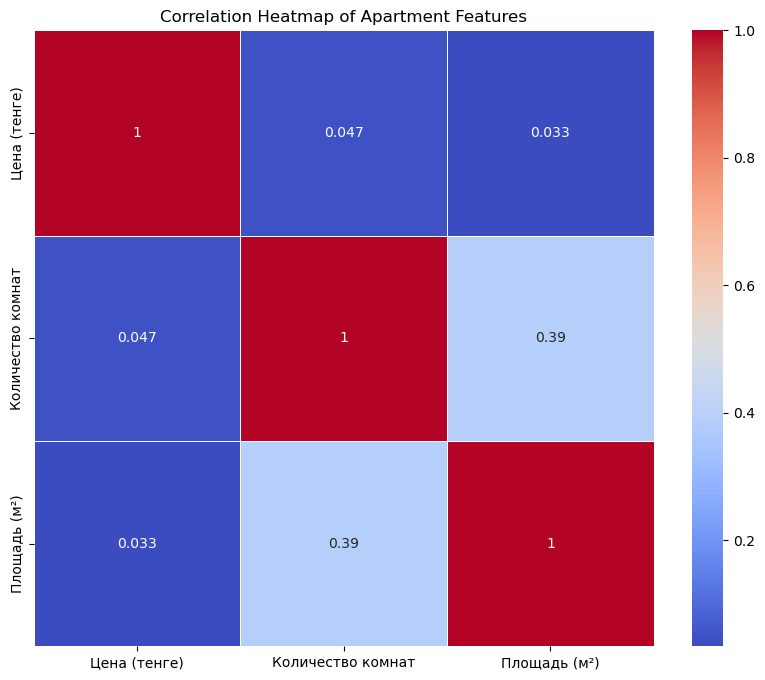

In [96]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("apartments_data_cleaned.csv")

# 1: Descriptive Statistics
# ------------------------------------------

# Mean
print("Mean Values:\n", df.mean(numeric_only=True))

# Median
# Median
print("\nMedian Values:\n", df.median(numeric_only=True))

# Mode
print("\nMode Values:\n", df.mode().iloc[0])

# Standard Deviation
print("\nStandard Deviation:\n", df.std(numeric_only=True))

# Displaying a summary statistics table for a quick overview
print("\nSummary Statistics:\n", df.describe())

# 2: Correlation Analysis
# ------------------------------------------
# Calculate correlation matrix using only numeric columns
correlation_matrix = df.corr(numeric_only=True)

# Display the correlation matrix
print("\nCorrelation Matrix:\n", correlation_matrix)

# Visualize correlation matrix using a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Apartment Features')
plt.show()

## 8. Price prediction

Three regression models are trained on an 80/20 split. Numeric features are standardized and text/categorical features are one-hot encoded inside a single scikit-learn `Pipeline`.

In [102]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load your dataset
df = pd.read_csv('apartments_data_trainlast.csv')

# Step 1: Data Preparation
# ------------------------------------------

# Define features (X) and target (y)
X = df.drop(columns=['Цена (тенге)'])
y = df['Цена (тенге)']

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(include=['object']).columns
numerical_features = X.select_dtypes(exclude=['object']).columns

# Preprocessing for numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Model Training and Evaluation
# ------------------------------------------

# Define a function to train and evaluate models
def train_and_evaluate_model(model, model_name):
    # Create a pipeline with preprocessing and the model
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('model', model)])
    # Train the model
    pipeline.fit(X_train, y_train)
    
    # Make predictions
    y_pred = pipeline.predict(X_test)
    
    # Evaluate the model
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    # Print evaluation metrics
    print(f"\n{model_name} Performance:")
    print(f"Mean Absolute Error (MAE): {mae}")
    print(f"Mean Squared Error (MSE): {mse}")
    print(f"R-squared Score: {r2}")

# Linear Regression
train_and_evaluate_model(LinearRegression(), "Linear Regression")

# Decision Tree Regression
train_and_evaluate_model(DecisionTreeRegressor(random_state=42), "Decision Tree Regression")

# Random Forest Regression
train_and_evaluate_model(RandomForestRegressor(random_state=42), "Random Forest Regression")



Linear Regression Performance:
Mean Absolute Error (MAE): 0.0006662353342294936
Mean Squared Error (MSE): 9.588358297856788e-07
R-squared Score: 0.5384012774330222

Decision Tree Regression Performance:
Mean Absolute Error (MAE): 0.0005977852339719096
Mean Squared Error (MSE): 1.1659624250256656e-06
R-squared Score: 0.43868726091176213

Random Forest Regression Performance:
Mean Absolute Error (MAE): 0.00055040358586749
Mean Squared Error (MSE): 1.1073908920494237e-06
R-squared Score: 0.46688452259175817


## 9. Results & next steps

| Model | R² (test) |
|---|---|
| **Linear Regression** | **0.54** |
| Random Forest | 0.47 |
| Decision Tree | 0.44 |

Linear Regression performed best. With only rooms, area, region and listing text available, about half of the price variation is explained — price also depends on district, building age, condition and floor, which were not in the data.

**Next improvements**
- Fix area parsing for decimal values (e.g. `56.8 м²` is currently read as `8`): use `r'(\d+(?:\.\d+)?)\s*м²'`
- Remove extreme price outliers (max listing ≈ 26 billion ₸ is almost certainly a typo)
- Recover the city for listings where it was missing instead of defaulting to Central
- Report MAE in real tenge (train on unscaled price) and try gradient boosting